# Práctico 3 — Aprendizaje Supervisado y No Supervisado
## DiploDatos 2026 · Ciencia de Datos Aplicada al Fútbol

**Objetivos de aprendizaje**
- Implementar el framework VAEP (Valuing Actions by Estimating Probabilities) completo
- Implementar y comparar el framework xT (Expected Threat)
- Usar XGBoost y LightGBM para predicción de valor de acciones
- Interpretar modelos con SHAP (SHapley Additive exPlanations)
- Aplicar clustering (K-Means + UMAP) para identificar perfiles de jugadores
- Construir un sistema de scouting basado en similitud

**Referencias clave**:
- Decroos et al. (2019) *Actions Speak Louder than Goals: Valuing Player Actions in Football*
- Van Roy et al. (2020) *Valuing on-the-ball actions in soccer: a critical comparison of XT and VAEP*
- Singh (2019) *Introducing Expected Threat* (blog)

---

In [119]:
# Instalación de dependencias
#!pip install socceraction xgboost lightgbm shap umap-learn scikit-learn pandas numpy matplotlib mplsoccer

In [60]:
import warnings
import numpy as np
import pandas as pd
import json
import codecs
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from mplsoccer import Pitch, VerticalPitch

# ML
import xgboost as xgb
import lightgbm as lgb
import shap
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
import umap

# socceraction
import socceraction.spadl as spadl
import socceraction.vaep.features as features
import socceraction.vaep.labels as labels
import socceraction.vaep.formula as vaep_formula

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('✓ Librerías cargadas')

✓ Librerías cargadas


In [61]:
# Cargamos el dataset curado del Práctico 2
from pathlib import Path

dataset_path = Path("./spadl_curado_PL_2017.parquet")
if not dataset_path.exists():
    dataset_path = Path("../data/processed/spadl_curado_PL_2017.parquet")
if not dataset_path.exists():
    dataset_path = Path("spadl_curado_PL_2017.parquet")

df_clean = pd.read_parquet(dataset_path)
print(f"Dataset cargado: {df_clean.shape}")
print(f"Partidos únicos: {df_clean['game_id'].nunique()} | Jugadores únicos: {df_clean['player_id'].nunique()}")


Dataset cargado: (2321340, 27)
Partidos únicos: 1826 | Jugadores únicos: 2567


In [62]:
# Ajustamos codificacion de caracteres especiales
df_clean['short_name']=df_clean['short_name'].apply(lambda x: codecs.decode(x, 'unicode_escape') if isinstance(x, str) else x)
df_clean['team_name']=df_clean['team_name'].apply(lambda x: codecs.decode(x, 'unicode_escape') if isinstance(x, str) else x)

Acciones sin jugador asignado:

In [120]:
df_clean[df_clean['player_id']==0]

,game_id,period_id,time_seconds,team_id,player_id,start_x,start_y,end_x,end_y,bodypart_id,type_id,result_id,type_name,result_name,bodypart_name,action_type_id,short_name,team_name,zone_x,carril,dist_goal,angle_goal,dist_moved,movement_dir,last_third,in_box,time_delta,cell_x,cell_y,end_cell_x,end_cell_y,xT_start,xT_end,xT_added
28,2499719,1,74.737141,1609,0,68.25,38.08,68.25,46.92,0,4,1,freekick_short,success,foot,4,None,Arsenal FC,mediocampo_alto,central,36.975788,6.335058,8.840000,lateral,0,0,20.370941,10,6,10,8,0.013654,0.013651,-0.000002
210,2499719,1,1012.237852,1609,0,26.25,22.44,38.85,15.64,0,4,1,freekick_short,success,foot,4,None,Arsenal FC,mediocampo_bajo,banda_izq,79.593945,8.351014,14.317821,hacia_adelante,0,0,19.320728,4,3,5,2,0.014776,0.013299,-0.001477
332,2499719,1,1415.509447,1609,0,90.30,54.40,95.55,50.32,0,7,0,take_on,fail,foot,7,None,Arsenal FC,ataque,banda_der,25.144582,54.223922,6.648977,hacia_adelante,1,0,0.049835,13,9,14,8,0.021690,0.027216,0.005526
367,2499719,1,1543.184289,1609,0,77.70,25.16,74.55,27.88,0,7,1,take_on,success,foot,7,None,Arsenal FC,mediocampo_alto,central,28.695568,17.942447,4.161839,lateral,1,0,0.741724,11,4,11,4,0.015387,0.015387,0.000000
526,2499719,1,2182.033494,1609,0,27.30,28.56,35.70,17.00,0,4,1,freekick_short,success,foot,4,None,Arsenal FC,mediocampo_bajo,central,77.890202,4.004907,14.289633,hacia_adelante,0,0,17.727921,4,5,5,3,0.014955,0.013012,-0.001943
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2320787,2576338,2,353.907286,3185,0,74.55,30.60,10.50,44.20,0,4,1,freekick_short,success,foot,4,None,Torino FC,mediocampo_alto,central,30.639231,6.371168,65.477954,hacia_atras,1,0,16.056359,11,5,1,7,0.015733,0.033974,0.018241
2321070,2576338,2,1578.278676,3185,0,73.50,63.24,79.80,18.36,0,4,1,freekick_short,success,foot,4,None,Torino FC,mediocampo_alto,banda_der,42.979386,42.869135,45.320022,hacia_adelante,1,0,9.199582,11,11,12,3,0.014946,0.018687,0.003741
2321283,2576338,2,2633.465692,3193,0,45.15,55.08,63.00,53.04,0,21,1,dribble,success,foot,21,None,Genoa CFC,mediocampo,banda_der,63.453833,19.402971,17.966193,hacia_adelante,0,0,2.737728,6,9,9,9,0.012267,0.012551,0.000284
2321284,2576338,2,2636.203420,3193,0,63.00,53.04,65.10,55.08,0,7,1,take_on,success,foot,7,None,Genoa CFC,mediocampo_alto,banda_der,46.114223,24.386371,2.927729,lateral,0,0,2.737728,9,9,9,9,0.012551,0.012551,0.000000


## PARTE A — Aprendizaje Supervisado

## 1. Framework xT (Expected Threat)

xT fue propuesto por Karun Singh en 2019. La idea central: el campo se divide en zonas y
a cada zona se le asigna un valor que refleja cuán amenazante es estar ahí.

**Formalmente**: xT(z) = P(shoot|z) × P(goal|shoot, z) + P(move|z) × Σ P(move to z'|move, z) × xT(z')

Es un modelo iterativo que converge en ~10 iteraciones.

In [63]:
def compute_xt_grid(df_actions: pd.DataFrame, M: int = 16, N: int = 12, 
                    n_iter: int = 10) -> tuple:
    """
    Implementación del modelo xT (Expected Threat).
    
    Parámetros
    ----------
    df_actions : DataFrame SPADL
    M, N       : dimensiones de la grilla (M columnas, N filas)
    n_iter     : iteraciones hasta convergencia
    
    Retorna
    -------
    (xT, pct_shoot, pct_goal) : arrays (M, N) con valores de amenaza por zona
    """
    # Asignamos cada acción a su celda de grilla
    df = df_actions.copy()
    df["cell_x"] = np.clip((df["start_x"] / 105 * M).astype(int), 0, M-1)
    df["cell_y"] = np.clip((df["start_y"] / 68 * N).astype(int), 0, N-1)
    df["end_cell_x"] = np.clip((df["end_x"].fillna(df["start_x"]) / 105 * M).astype(int), 0, M-1)
    df["end_cell_y"] = np.clip((df["end_y"].fillna(df["start_y"]) / 68 * N).astype(int), 0, N-1)
    
    # Máscara de tiros
    shot_names = ["shot", "shot_penalty", "penalty_shot", "shot_freekick", "freekick_shot"]
    shots = df[df["type_name"].isin(shot_names)]
    moves = df[~df["type_name"].isin(shot_names)]
    
    pct_shoot = np.zeros((M, N))
    pct_goal  = np.zeros((M, N))
    pct_move  = np.zeros((M, N))
    
    for (cx, cy), group in df.groupby(["cell_x", "cell_y"]):
        n_total = len(group)
        n_shots = len(group[group["type_name"].isin(shot_names)])
        n_goals = len(group[(group["type_name"].isin(shot_names)) & (group["result_name"] == "success")])
        pct_shoot[cx, cy] = n_shots / max(n_total, 1)
        pct_goal[cx, cy]  = n_goals / max(n_shots, 1)
        pct_move[cx, cy]  = 1 - pct_shoot[cx, cy]

    # Matriz de transición de movimientos P(z' | z) optimizada
    transition = np.zeros((M, N, M, N))
    total_from_dict = moves.groupby(["cell_x", "cell_y"]).size().to_dict()
    for (cx, cy, ecx, ecy), count in moves.groupby(
        ["cell_x", "cell_y", "end_cell_x", "end_cell_y"]
    ).size().items():
        tf = total_from_dict.get((cx, cy), 0)
        if tf > 0:
            transition[cx, cy, ecx, ecy] = count / tf

    # Iteración de valor (Value Iteration)
    xT = np.zeros((M, N))
    for iteration in range(n_iter):
        xT_prev = xT.copy()
        # Valor de mover = suma ponderada de xT de destinos
        move_value = np.einsum("xyzw,zw->xy", transition, xT_prev)
        xT = pct_shoot * pct_goal + pct_move * move_value
        delta = np.max(np.abs(xT - xT_prev))
        if (iteration + 1) % 2 == 0:
            print(f"  Iteración {iteration+1}: Δmax = {delta:.6f}")

    return xT, pct_shoot, pct_goal

print("Computando grilla xT (M=16, N=12)...")
xT_grid, pshot_grid, pgoal_grid = compute_xt_grid(df_clean, M=16, N=12, n_iter=10)


Computando grilla xT (M=16, N=12)...
  Iteración 2: Δmax = 0.015030
  Iteración 4: Δmax = 0.003929
  Iteración 6: Δmax = 0.002385
  Iteración 8: Δmax = 0.001836
  Iteración 10: Δmax = 0.001666


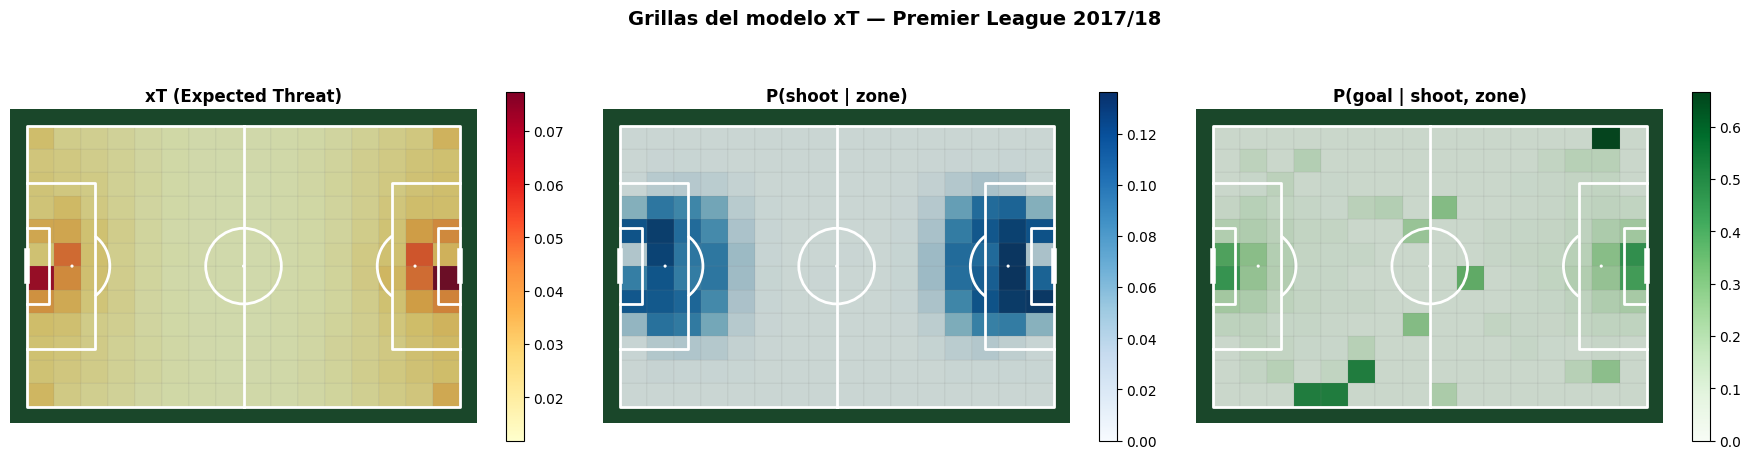

In [64]:
# Visualización de la grilla xT
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
titles = ['xT (Expected Threat)', 'P(shoot | zone)', 'P(goal | shoot, zone)']
grids  = [xT_grid, pshot_grid, pgoal_grid]
cmaps  = ['YlOrRd', 'Blues', 'Greens']

for ax, title, grid, cmap in zip(axes, titles, grids, cmaps):
    pitch = Pitch(pitch_type='custom', pitch_length=105, pitch_width=68,
                  pitch_color='#1a472a', line_color='white', line_zorder=2)
    pitch.draw(ax=ax)
    M, N = grid.shape
    # Dibujamos cada celda
    norm = mcolors.Normalize(vmin=grid.min(), vmax=grid.max())
    cmap_obj = plt.get_cmap(cmap)
    for i in range(M):
        for j in range(N):
            x0 = i * 105 / M
            y0 = j * 68 / N
            rect = plt.Rectangle(
                (x0, y0), 105/M, 68/N,
                linewidth=0.1, edgecolor='gray',
                facecolor=cmap_obj(norm(grid[i, j])),
                alpha=0.8
            )
            ax.add_patch(rect)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    plt.colorbar(sm, ax=ax, shrink=0.8)
    ax.set_title(title, fontsize=12, fontweight='bold')

plt.suptitle('Grillas del modelo xT — Premier League 2017/18', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [65]:
# Asignamos el valor xT a cada acción
M, N = xT_grid.shape

df_clean["cell_x"]     = np.clip((df_clean["start_x"] / 105 * M).astype(int), 0, M-1)
df_clean["cell_y"]     = np.clip((df_clean["start_y"] / 68 * N).astype(int), 0, N-1)
df_clean["end_cell_x"] = np.clip((df_clean["end_x"].fillna(df_clean["start_x"]) / 105 * M).astype(int), 0, M-1)
df_clean["end_cell_y"] = np.clip((df_clean["end_y"].fillna(df_clean["start_y"]) / 68 * N).astype(int), 0, N-1)

# Indexación vectorizada de NumPy (alta performance)
df_clean["xT_start"] = xT_grid[df_clean["cell_x"].values, df_clean["cell_y"].values]
df_clean["xT_end"]   = xT_grid[df_clean["end_cell_x"].values, df_clean["end_cell_y"].values]
df_clean["xT_added"] = df_clean["xT_end"] - df_clean["xT_start"]

# Solo para acciones que mueven el balón (no tiros)
shot_names = ["shot", "shot_penalty", "penalty_shot", "shot_freekick", "freekick_shot"]
mask_moves = ~df_clean["type_name"].isin(shot_names)

print("Top 10 acciones por xT añadido (positivo):")
cols_show = ["game_id", "player_id", "short_name", "type_name", "xT_start", "xT_end", "xT_added"]
cols_show = [c for c in cols_show if c in df_clean.columns]
print(df_clean[mask_moves].nlargest(10, "xT_added")[cols_show].to_string(index=False))


Top 10 acciones por xT añadido (positivo):
 game_id  player_id    short_name type_name  xT_start   xT_end  xT_added
 2516829      70096  J. Rodríguez      pass  0.011975 0.077368  0.065393
 2500809      27354 Júlio Tavares   dribble  0.011999 0.077368  0.065369
 2516767      19392    M. Philipp   dribble  0.011999 0.077368  0.065369
 2499842       8495 D. Drinkwater      pass  0.012050 0.077368  0.065318
 2517040     471348   W. McKennie      pass  0.012050 0.077368  0.065318
 2516749     173214     T. Werner   dribble  0.012063 0.077368  0.065305
 2516816      14929     M. Hasebe      pass  0.012086 0.077368  0.065282
 2499850      26010     O. Giroud   dribble  0.012094 0.077368  0.065274
 2499998       8360     C. Dawson   dribble  0.012094 0.077368  0.065274
 2500868      27958  T. Pellenard      pass  0.012094 0.077368  0.065274


In [66]:
# Ranking de jugadores por xT añadido (normalizado por partido)
games_per_player = df_clean.groupby("player_id")["game_id"].nunique().reset_index()
games_per_player.columns = ["player_id", "games"]

# Diccionario para asociar short_name a cada jugador
player_names = df_clean.dropna(subset=["short_name"]).groupby("player_id")["short_name"].last().to_dict() if "short_name" in df_clean.columns else {}

xt_by_player = df_clean[mask_moves].groupby("player_id").agg(
    xT_total=("xT_added", "sum"),
    n_actions=("xT_added", "count")
).reset_index()

xt_by_player = xt_by_player.merge(games_per_player, on="player_id")
xt_by_player = xt_by_player[xt_by_player["games"] >= 10]
xt_by_player["xT_p90"] = xt_by_player["xT_total"] / xt_by_player["games"]
xt_by_player["jugador"] = xt_by_player["player_id"].map(player_names).fillna(xt_by_player["player_id"].astype(str))

print("Top 15 jugadores por xT añadido por partido:")
print(
    xt_by_player.sort_values("xT_p90", ascending=False)
    .head(15)[["player_id", "jugador", "xT_total", "n_actions", "games", "xT_p90"]]
    .to_string(index=False)
)


Top 15 jugadores por xT añadido por partido:
 player_id        jugador  xT_total  n_actions  games   xT_p90
     40810         Neymar  4.876702       1893     20 0.243835
     38021   K. De Bruyne  8.794332       3437     37 0.237685
      3484   Luis Alberto  7.401308       2214     34 0.217686
     25714       D. Payet  6.701618       1918     31 0.216181
      4379 Jonathan Viera  4.781130       1858     23 0.207875
      3319        M. Özil  5.216294       2235     26 0.200627
      3359       L. Messi  7.152269       2560     36 0.198674
      4014     Pedro León  2.369609        571     12 0.197467
     25770     F. Thauvin  6.765544       2388     35 0.193301
     21077       A. Gómez  6.368916       2012     33 0.192997
        54     C. Eriksen  7.095756       2862     37 0.191777
     20436     José Ángel  5.684623       1987     30 0.189487
      3361     A. Sánchez  5.798431       1971     31 0.187046
    224593     J. Kimmich  5.174741       2498     28 0.184812
     21123

## 2. Framework VAEP (Valuing Actions by Estimating Probabilities)

VAEP va más allá de xT al usar aprendizaje supervisado para estimar:
- **P(score)**: probabilidad de que el equipo que tiene el balón anote en los próximos 10 acciones
- **P(concede)**: probabilidad de que el equipo que tiene el balón reciba un gol en las próximas 10 acciones

El valor de una acción es: `VAEP(a) = ΔP(score) - ΔP(concede)`

In [67]:
# Generamos game states (contexto de 3 acciones previas)
print("Generando game states...")
gamestates = features.gamestates(df_clean, nb_prev_actions=3)

# Features para el modelo VAEP
feat_fns = [
    features.actiontype_onehot,
    features.result_onehot,
    features.bodypart_onehot,
    features.time,
    features.startlocation,
    features.endlocation,
    features.movement,
    features.startpolar,
    features.endpolar,
    features.team,
]

X_vaep = pd.concat(
    [fn(gamestates) for fn in feat_fns],
    axis=1
).fillna(0)

print(f"Features: {X_vaep.shape[1]} columnas x {X_vaep.shape[0]:,} acciones")


Generando game states...
Features: 143 columnas x 2,321,340 acciones


In [68]:
# Labels: P(score) y P(concede)
ys = pd.concat([
    labels.scores(df_clean, nr_actions=10),
    labels.concedes(df_clean, nr_actions=10)
], axis=1)

print("Distribución de labels:")
print(f"  Scoring (gol en ≤10 acciones): {ys['scores'].mean():.3%}")
print(f"  Conceding (gol en contra en ≤10): {ys['concedes'].mean():.3%}")
print(f"  Total acciones: {len(ys):,}")


Distribución de labels:
  Scoring (gol en ≤10 acciones): 1.559%
  Conceding (gol en contra en ≤10): 0.502%
  Total acciones: 2,321,340


In [69]:
def train_vaep_model(X: pd.DataFrame, y: pd.Series, 
                     model_type: str = "xgboost") -> tuple:
    """
    Entrena un modelo para VAEP con validación cruzada estratificada.
    
    Parámetros
    ----------
    X          : features
    y          : label (scores o concedes)
    model_type : "xgboost" o "lightgbm"
    
    Retorna
    -------
    (model, y_pred_proba, metrics)
    """
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    
    if model_type == "xgboost":
        model = xgb.XGBClassifier(
            n_estimators=100,
            max_depth=3,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    else:  # lightgbm
        model = lgb.LGBMClassifier(
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbose=-1
        )

    # Predicciones out-of-fold
    y_pred = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    model.fit(X, y)  # Entrenamos en todo para inferencia y SHAP

    metrics = {
        "AUC": roc_auc_score(y, y_pred),
        "Brier": brier_score_loss(y, y_pred),
        "Base_rate": y.mean()
    }

    return model, y_pred, metrics

# Entrenamos los dos modelos VAEP
print("Entrenando modelo P(score)...")
model_score, pred_score, metrics_score = train_vaep_model(
    X_vaep, ys["scores"], model_type="xgboost"
)
print(f"  AUC={metrics_score['AUC']:.4f} | Brier={metrics_score['Brier']:.4f}")

print("Entrenando modelo P(concede)...")
model_concede, pred_concede, metrics_concede = train_vaep_model(
    X_vaep, ys["concedes"], model_type="xgboost"
)
print(f"  AUC={metrics_concede['AUC']:.4f} | Brier={metrics_concede['Brier']:.4f}")


Entrenando modelo P(score)...
  AUC=0.7402 | Brier=0.0131
Entrenando modelo P(concede)...
  AUC=0.7297 | Brier=0.0049


In [70]:
# Computamos los valores VAEP
# VAEP(a) = ΔP(score) - ΔP(concede)

df_vaep = df_clean.copy()
df_vaep["p_score"]   = pred_score
df_vaep["p_concede"] = pred_concede

# El valor se calcula como el delta respecto al estado anterior (requiere pd.Series)
values = vaep_formula.value(
    df_clean, 
    pd.Series(pred_score, index=df_clean.index), 
    pd.Series(pred_concede, index=df_clean.index)
)

df_vaep["vaep_value"] = values["vaep_value"]
df_vaep["off_value"]  = values["offensive_value"]
df_vaep["def_value"]  = values["defensive_value"]

print("Estadísticas de valor VAEP:")
print(df_vaep["vaep_value"].describe())


Estadísticas de valor VAEP:
count    2.321340e+06
mean     2.995607e-03
std      4.317981e-02
min     -7.932149e-01
25%     -2.189743e-03
50%      9.367030e-04
75%      5.037059e-03
max      1.027530e+00
Name: vaep_value, dtype: float64


In [71]:
# Ranking de jugadores por VAEP
vaep_by_player = df_vaep.groupby("player_id").agg(
    vaep_total=("vaep_value", "sum"),
    off_total=("off_value", "sum"),
    def_total=("def_value", "sum"),
    n_actions=("vaep_value", "count")
).reset_index()

vaep_by_player = vaep_by_player.merge(games_per_player, on="player_id")
vaep_by_player = vaep_by_player[vaep_by_player["games"] >= 10]
vaep_by_player["vaep_p90"] = vaep_by_player["vaep_total"] / vaep_by_player["games"]
vaep_by_player["jugador"] = vaep_by_player["player_id"].map(player_names).fillna(vaep_by_player["player_id"].astype(str))

print("\n=== TOP 15 JUGADORES POR VAEP POR PARTIDO ===")
print(
    vaep_by_player.sort_values("vaep_p90", ascending=False)
    .head(15)[["player_id", "jugador", "vaep_total", "off_total", "def_total", "games", "vaep_p90"]]
    .to_string(index=False)
)



=== TOP 15 JUGADORES POR VAEP POR PARTIDO ===
 player_id           jugador  vaep_total  off_total  def_total  games  vaep_p90
      3359          L. Messi   32.771045  34.935185  -2.164139     36  0.910307
     40810            Neymar   17.242383  18.793414  -1.551031     20  0.862119
    120353     Mohamed Salah   27.803628  28.784397  -0.980770     36  0.772323
      3322 Cristiano Ronaldo   18.588442  19.749812  -1.161370     27  0.688461
      8717           H. Kane   21.997462  23.149743  -1.152280     37  0.594526
      8325         S. Agüero   14.710984  15.616151  -0.905168     25  0.588439
     21174         E. Cavani   18.403589  19.470951  -1.067362     32  0.575112
     14817    R. Lewandowski   17.078948  18.881782  -1.802834     30  0.569298
     21384       C. Immobile   18.666712  19.693834  -1.027122     33  0.565658
      8278           G. Bale   14.551304  15.250088  -0.698784     26  0.559666
      3840        Iago Aspas   18.963681  19.707648  -0.743967     34  0.

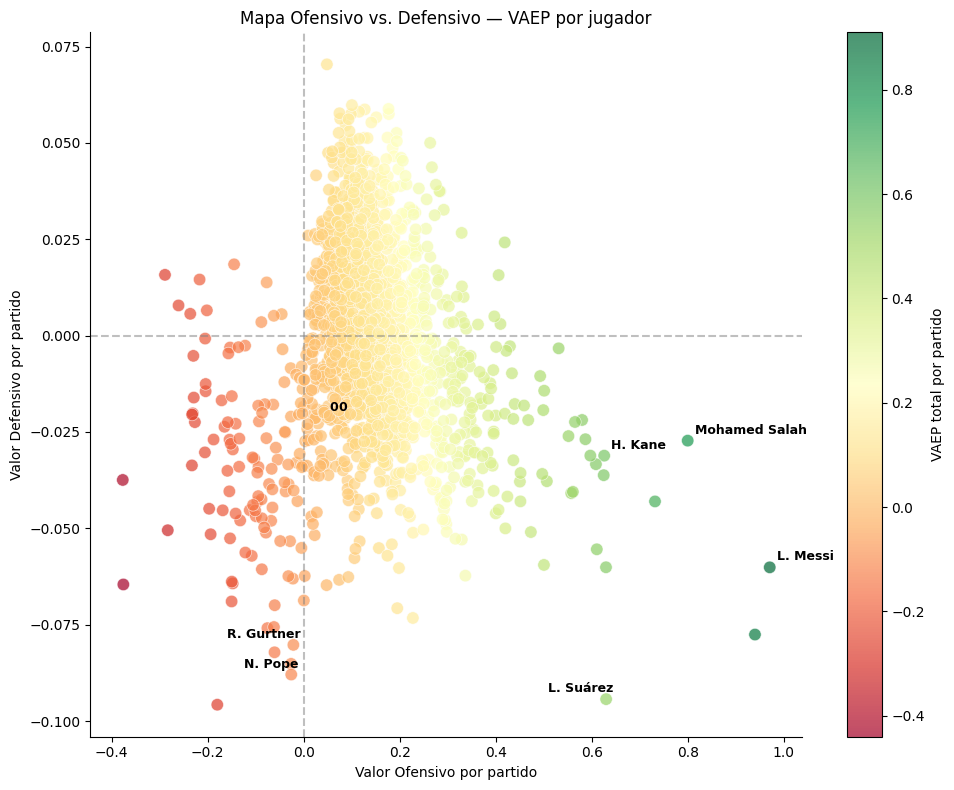

In [121]:
# Visualización: valor ofensivo vs defensivo
fig, ax = plt.subplots(figsize=(10, 8))

top_players = vaep_by_player[vaep_by_player["games"] >= 15]
scatter = ax.scatter(
    top_players["off_total"] / top_players["games"],
    top_players["def_total"] / top_players["games"],
    c=top_players["vaep_p90"],
    cmap="RdYlGn",
    s=80, alpha=0.7, edgecolors="white", linewidth=0.5
)
plt.colorbar(scatter, label="VAEP total por partido")

ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
ax.axvline(0, color="gray", linestyle="--", alpha=0.5)
ax.set_xlabel("Valor Ofensivo por partido")
ax.set_ylabel("Valor Defensivo por partido")
ax.set_title("Mapa Ofensivo vs. Defensivo — VAEP por jugador")
ax.spines[["top","right"]].set_visible(False)

# Etiquetas para extremos con nombres legibles
for label, df_label, ha in [
    ("Más ofensivos", top_players.nlargest(4, "off_total"), "left"),
    ("Más defensivos", top_players.nsmallest(4, "def_total"), "right")
]:
    for _, row in df_label.iterrows():
        display_txt = row["jugador"] if pd.notna(row.get("jugador")) else str(int(row["player_id"]))
        ax.annotate(
            display_txt,
            (row["off_total"]/row["games"], row["def_total"]/row["games"]),
            xytext=(5, 5), textcoords="offset points",
            fontsize=9, fontweight="bold", ha=ha
        )

plt.tight_layout()
plt.show()


## 3. Explicabilidad con SHAP

Los modelos de gradient boosting son cajas negras. SHAP nos permite entender
la contribución de cada feature a cada predicción individual.

Calculando SHAP values...


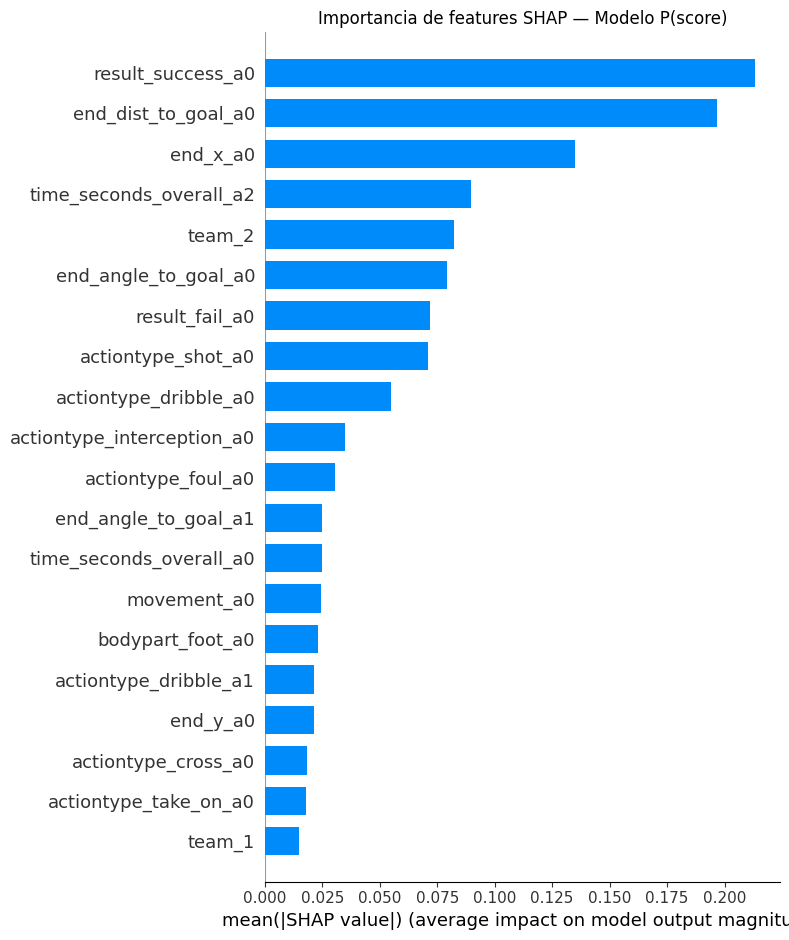

In [73]:
# Calculamos SHAP values para el modelo de scoring
print('Calculando SHAP values...')

# Muestra representativa (SHAP es costoso en datasets grandes)
sample_idx = np.random.choice(len(X_vaep), min(2000, len(X_vaep)), replace=False)
X_sample = X_vaep.iloc[sample_idx]

explainer = shap.TreeExplainer(model_score)
shap_values = explainer.shap_values(X_sample)

# Summary plot — las features más importantes globalmente
plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values, X_sample, 
    plot_type='bar',
    max_display=20,
    show=False
)
plt.title('Importancia de features SHAP — Modelo P(score)', fontsize=12)
plt.tight_layout()
plt.show()

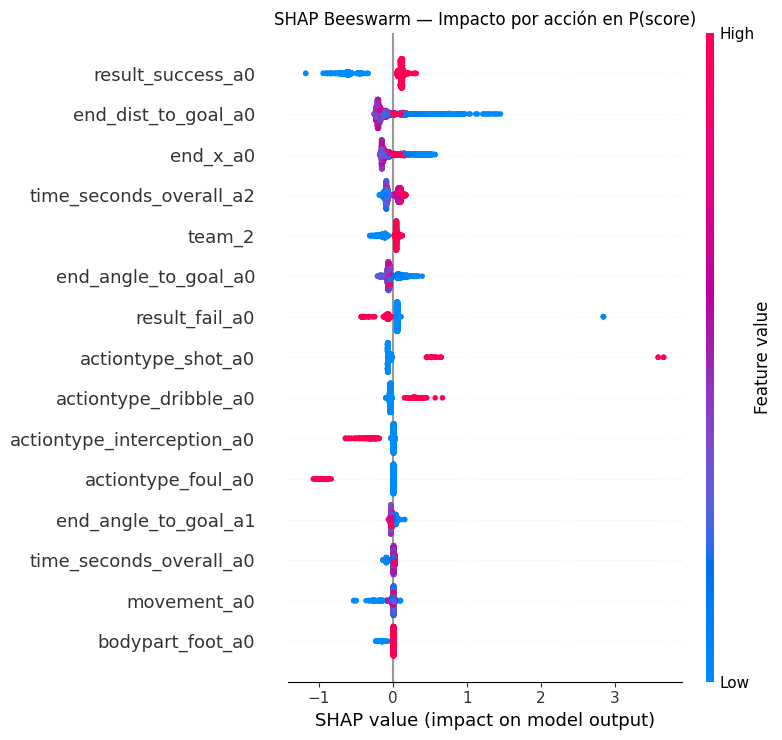

In [74]:
# SHAP Beeswarm plot — distribución del impacto
plt.figure(figsize=(10, 10))
shap.summary_plot(
    shap_values, X_sample,
    max_display=15,
    show=False
)
plt.title('SHAP Beeswarm — Impacto por acción en P(score)', fontsize=12)
plt.tight_layout()
plt.show()

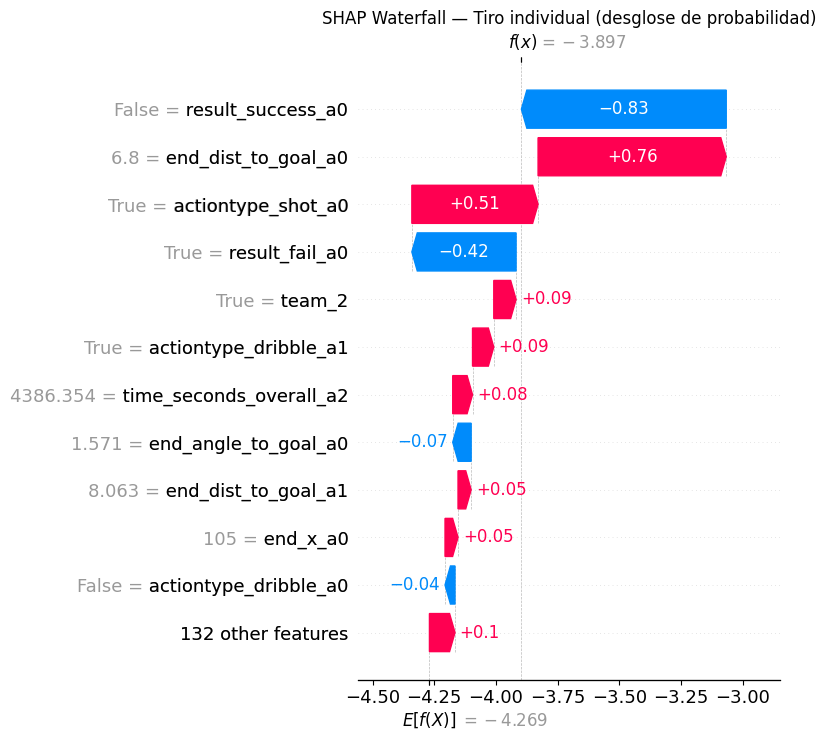

In [75]:
# SHAP waterfall para una acción específica (por ejemplo, un gol o tiro)
shot_names = ["shot", "shot_penalty", "penalty_shot", "shot_freekick", "freekick_shot"]
shot_idx = X_sample.index[
    df_vaep.loc[X_sample.index, "type_name"].isin(shot_names)
].tolist()

if len(shot_idx) > 0:
    idx = shot_idx[0]
    relative_idx = X_sample.index.get_loc(idx)
    
    exp_val = explainer.expected_value
    if isinstance(exp_val, (list, np.ndarray)):
        exp_val = float(exp_val[1] if len(exp_val) > 1 else exp_val[0])
    
    shap_exp = shap.Explanation(
        values=shap_values[relative_idx],
        base_values=exp_val,
        data=X_sample.iloc[relative_idx].values,
        feature_names=X_sample.columns.tolist()
    )
    plt.figure(figsize=(10, 6))
    shap.waterfall_plot(shap_exp, max_display=12, show=False)
    plt.title("SHAP Waterfall — Tiro individual (desglose de probabilidad)", fontsize=12)
    plt.tight_layout()
    plt.show()


## 4. Comparación VAEP vs xT

Ambos frameworks valoran acciones, pero con enfoques distintos.
Analizamos en qué casos difieren más.

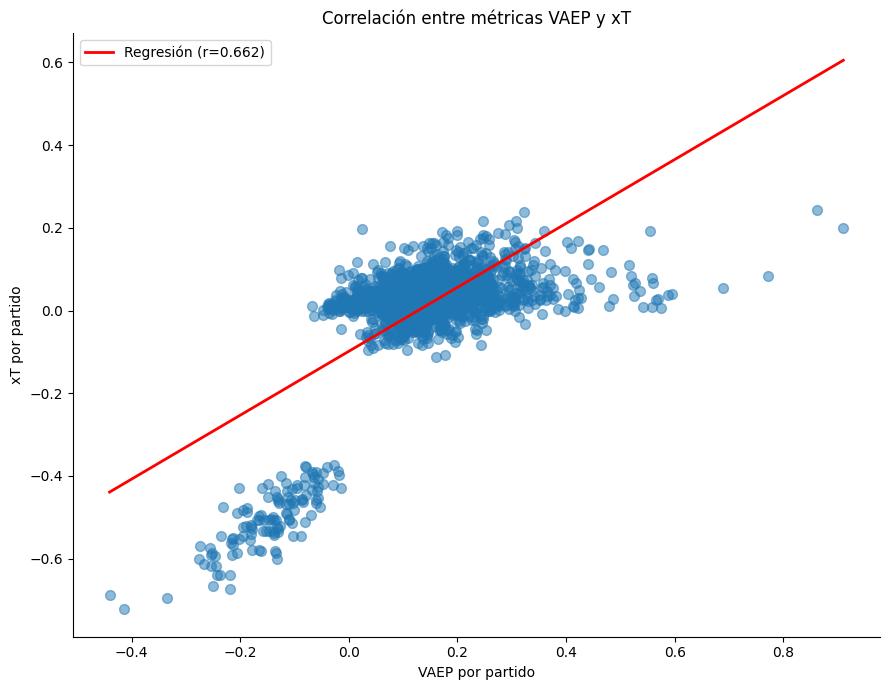

Correlación Pearson VAEP-xT: 0.6622

¿Por qué hay discrepancias? VAEP incluye valor defensivo, xT solo valora el movimiento del balón.


In [76]:
# Merge de rankings VAEP y xT
comparison = vaep_by_player.merge(
    xt_by_player[['player_id', 'xT_p90']],
    on='player_id', how='inner'
)

# Correlación entre ambas métricas
corr = comparison[['vaep_p90', 'xT_p90']].corr().iloc[0, 1]

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(comparison['vaep_p90'], comparison['xT_p90'], alpha=0.5, s=50)
# Línea de tendencia
m, b = np.polyfit(comparison['vaep_p90'], comparison['xT_p90'], 1)
x_line = np.linspace(comparison['vaep_p90'].min(), comparison['vaep_p90'].max(), 100)
ax.plot(x_line, m*x_line + b, color='red', linewidth=2, label=f'Regresión (r={corr:.3f})')

ax.set_xlabel('VAEP por partido')
ax.set_ylabel('xT por partido')
ax.set_title('Correlación entre métricas VAEP y xT')
ax.legend()
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

print(f'Correlación Pearson VAEP-xT: {corr:.4f}')
print('\n¿Por qué hay discrepancias? VAEP incluye valor defensivo, xT solo valora el movimiento del balón.')

## PARTE B — Aprendizaje No Supervisado

## 5. Clustering de jugadores

Queremos identificar perfiles de juego de manera automática, sin etiquetas previas.
Esto permite descubrir patrones emergentes y similitudes entre jugadores.

Antes que nada separamos las acciones de los arqueros ya que nos van a distorsionar la identificación de los arquetipos de jugadores que buscamos.

In [177]:
# 1. Cargar metadatos de jugadores para obtener la posición/rol
players_path = Path("../data/players.json")
if not players_path.exists():
    players_path = Path("data/players.json")
with open(players_path, "r", encoding="utf-8") as f:
    players_data = json.load(f)
# 2. Diccionario wyId (player_id) -> posición ('Goalkeeper', 'Defender', 'Midfielder', 'Forward')
player_role_map = {
    p["wyId"]: p.get("role", {}).get("name", "Unknown") if isinstance(p.get("role"), dict) else "Unknown"
    for p in players_data
}
# 3. Asignar la posición a cada acción
df_vaep["role_name"] = df_vaep["player_id"].map(player_role_map).fillna("Unknown")
# 4. Separar las acciones de arqueros en un nuevo dataset
df_vaep_gk = df_vaep[df_vaep["role_name"] == "Goalkeeper"].copy()
# 5. Mantener en df_vaep únicamente las acciones de jugadores de campo (sin arqueros)
df_vaep = df_vaep[df_vaep["role_name"] != "Goalkeeper"].copy()
# 6. Métricas y listado de acciones por posición en df_clean
print(f"✓ Acciones de campo (df_vaep):    {len(df_vaep):,}")
print(f"✓ Acciones de arqueros (df_vaep_gk): {len(df_vaep_gk):,}")
print("\nCantidad de acciones por posición en df_vaep:")
print(df_vaep["role_name"].value_counts())

✓ Acciones de campo (df_vaep):    2,171,398
✓ Acciones de arqueros (df_vaep_gk): 0

Cantidad de acciones por posición en df_vaep:
role_name
Defender      951011
Midfielder    891999
Forward       328388
Name: count, dtype: int64


In [240]:
# Construcción del perfil de cada jugador
# Usamos distribución de tipos de acción como vector de características

# Pivot: jugador × tipo de acción
action_profile = df_vaep.groupby(
    ['player_id', 'type_name']
).size().unstack(fill_value=0)

# Filtramos jugadores con suficientes acciones
min_actions = 100
action_profile = action_profile[action_profile.sum(axis=1) >= min_actions]

# Normalizamos: proporción de cada tipo de acción
action_profile_norm = action_profile.div(action_profile.sum(axis=1), axis=0)

# Añadimos métricas de valor
vaep_feats = vaep_by_player[
    vaep_by_player['player_id'].isin(action_profile.index)
].set_index('player_id')[['vaep_p90', 'off_total', 'def_total']]

# Merge del perfil completo
player_vectors = action_profile_norm.join(vaep_feats, how='inner')
player_vectors = player_vectors.fillna(0)

print(f'Jugadores para clustering: {len(player_vectors)}')
print(f'Dimensiones del vector: {player_vectors.shape[1]}')

Jugadores para clustering: 1816
Dimensiones del vector: 21


### Perfil ampliado del jugador: calidad de ejecución + zonas de la cancha

Además de la **distribución de tipos de acción** (qué hace), sumamos:

| Familia | Variables | Qué captura |
|---|---|---|
| Tasa de éxito | `succ_<tipo>` para pass, take_on, tackle, interception, cross, shot, clearance | *Qué tan bien* ejecuta (mín. 10 intentos; si no, mediana de su rol) |
| Profundidad | `zona_*` (proporción de acciones por zona) | Dónde juega: defensa propia → ataque |
| Lateralidad | `carril_*` | Banda izquierda / central / banda derecha |
| Progresión | `pct_last_third`, `pct_in_box`, `dist_mov_media` | Cuánto llega al último tercio y al área |
| Valor por zona | `vaep_zona_*` | Dónde genera VAEP |

`dribble` se excluye de las tasas de éxito porque casi siempre es exitoso (~99%) y no discrimina.

Se arman tres perfiles y se elige uno con `PERFIL`:
- `'base'`: el perfil original (tipos de acción + VAEP).
- `'completo'`: base + todas las variables nuevas.
- `'estilo'`: variables nuevas **sin métricas VAEP y sin freuencia de acciones original** (solo acciones ponderadas para estilo de juego).

In [241]:
# ── Variables nuevas ────────────────────────────────────────────────────────
key_types = ['pass', 'take_on', 'tackle', 'interception', 'cross', 'shot', 'clearance']
MIN_INTENTOS = 10

# 1. Tasa de éxito por tipo de acción
exito = (df_vaep['result_name'] == 'success').astype(int)
cnt   = df_vaep.groupby(['player_id', 'type_name']).size().unstack(fill_value=0)
succ  = exito.groupby([df_vaep['player_id'], df_vaep['type_name']]).mean().unstack()[key_types]
succ  = succ.where(cnt[key_types] >= MIN_INTENTOS)          # NaN si hay pocos intentos
succ.columns = [f'succ_{c}' for c in succ.columns]
roles = df_vaep.groupby('player_id')['role_name'].first()
# Imputación con la mediana del rol (no sesga al jugador que casi no hace esa acción)
succ  = succ.groupby(roles).transform(lambda s: s.fillna(s.median())).fillna(0)

# 2. Distribución por zona (profundidad) y carril (lateralidad)
zona = df_vaep.groupby(['player_id', 'zone_x']).size().unstack(fill_value=0)
zona = zona.div(zona.sum(axis=1), axis=0).add_prefix('zona_')
carril = df_vaep.groupby(['player_id', 'carril']).size().unstack(fill_value=0)
carril = carril.div(carril.sum(axis=1), axis=0).add_prefix('carril_')

# 3. Progresión con pelota
comport = df_vaep.groupby('player_id').agg(
    pct_last_third=('last_third', 'mean'),
    pct_in_box=('in_box', 'mean'),
    dist_mov_media=('dist_moved', 'mean'),
)

# 4. Dónde genera valor: VAEP por zona
vaep_zona = (df_vaep.pivot_table(index='player_id', columns='zone_x', values='vaep_value',
                                 aggfunc='sum', fill_value=0)
             .add_prefix('vaep_zona_'))

extra_estilo = succ.join([zona, carril, comport], how='left')
extra_todo   = extra_estilo.join(vaep_zona, how='left')

# ── Tres perfiles candidatos (mismo conjunto de jugadores) ──────────────────
idx = action_profile_norm.index.intersection(vaep_feats.index)
perfiles = {
    'base':     action_profile_norm.loc[idx].join(vaep_feats).fillna(0),
    'completo': action_profile_norm.loc[idx].join(vaep_feats).join(extra_todo).fillna(0),
    'estilo':   extra_estilo.loc[idx].fillna(0),
}

PERFIL = 'estilo'            # 'base' | 'completo' | 'estilo'
player_vectors = perfiles[PERFIL].copy()

print({k: v.shape for k, v in perfiles.items()})
print(f"Perfil activo: '{PERFIL}' -> {player_vectors.shape[0]} jugadores, {player_vectors.shape[1]} variables")

{'base': (1816, 21), 'completo': (1816, 44), 'estilo': (1816, 18)}
Perfil activo: 'estilo' -> 1816 jugadores, 18 variables


### Desicion metodológica. Para este caso utilizamos el perfil "estilo" para el clustering.

Al eliminar las 18 variables de frecuencias crudas (conteos absolutos de pases, remates, etc.) y conservar exclusivamente las 18 variables calculadas de estilo (tasas de efectividad por acción, distribución por carriles, zonificación longitudinal y métricas de progresión), eliminamos el sesgo de volumen de juego (minutos jugados y porcentaje de posesión del equipo).

Buscamos que el modelo de K-Means agrupe a los futbolistas por arquetipo funcional puro (el cómo y el dónde juegan).

**Luego agregaremos nuestros valores de xT y VAEP como complemento de performace ademas del estilo.**

In [242]:
# ── Comparación de perfiles: silhouette y alineación con la posición ───────
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

rol = roles.reindex(idx).fillna('Unknown')
filas = []
for nombre, Xp in perfiles.items():
    Xs = StandardScaler().fit_transform(Xp)
    res = {}
    for k in range(2, 12):
        lab = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(Xs)
        res[k] = (silhouette_score(Xs, lab), lab)
    k_opt = max(res, key=lambda k: res[k][0])
    for etiqueta, k in [('K óptimo (silhouette)', k_opt), ('K = 4 fijo', 4)]:
        sil, lab = res[k]
        filas.append({'perfil': nombre, 'variables': Xp.shape[1], 'criterio': etiqueta, 'K': k,
                      'silhouette': round(sil, 3),
                      'NMI vs rol': round(normalized_mutual_info_score(rol, lab), 3),
                      'ARI vs rol': round(adjusted_rand_score(rol, lab), 3)})

comparacion = pd.DataFrame(filas)
display(comparacion)

,perfil,variables,criterio,K,silhouette,NMI vs rol,ARI vs rol
0,base,21,K óptimo (silhouette),3,0.247,0.328,0.305
1,base,21,K = 4 fijo,4,0.194,0.365,0.275
2,completo,44,K óptimo (silhouette),2,0.150,0.181,0.126
3,completo,44,K = 4 fijo,4,0.135,0.441,0.355
4,estilo,18,K óptimo (silhouette),4,0.187,0.413,0.321
5,estilo,18,K = 4 fijo,4,0.187,0.413,0.321


**Cómo leer la tabla**

- `silhouette` mide cohesión/separación interna de los clusters: es **menos comparable entre perfiles** de distinta dimensión (con más variables baja casi siempre).
- `NMI` / `ARI` vs. rol miden cuánto se parecen los clusters a la posición (Defender / Midfielder / Forward). Un valor muy alto significaría que el clustering solo reproduce la posición; uno bajo, que encuentra perfiles que la cruzan (por ejemplo, laterales ofensivos, mediocampistas de contención).
- Cambiá `PERFIL` en la celda anterior y volvé a ejecutar el clustering (celdas siguientes) para ver los clusters con cada perfil.

## Estandarización y "K" óptimo


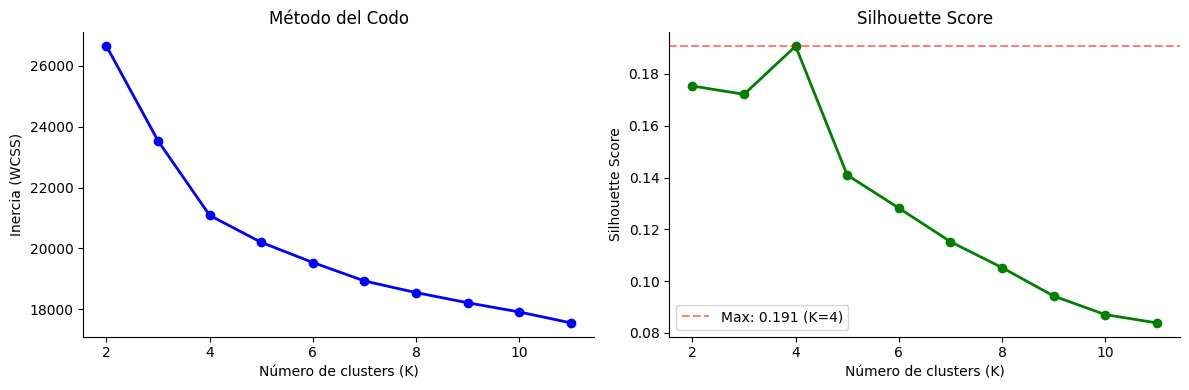


K óptimo por Silhouette: 4


In [243]:
# Estandarización antes de clustering
scaler = StandardScaler()
X_cluster = scaler.fit_transform(player_vectors)

# Método del codo para elegir K
inertias = []
silhouettes = []
K_range = range(2, 12)

from sklearn.metrics import silhouette_score

for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_k = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster, labels_k, sample_size=min(1000, len(X_cluster))))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K_range, inertias, 'bo-', linewidth=2)
axes[0].set_xlabel('Número de clusters (K)')
axes[0].set_ylabel('Inercia (WCSS)')
axes[0].set_title('Método del Codo')
axes[0].spines[['top','right']].set_visible(False)

axes[1].plot(K_range, silhouettes, 'go-', linewidth=2)
axes[1].set_xlabel('Número de clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score')
axes[1].axhline(max(silhouettes), color='red', linestyle='--', alpha=0.5,
                label=f'Max: {max(silhouettes):.3f} (K={K_range.start + silhouettes.index(max(silhouettes))})')
axes[1].legend()
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

OPTIMAL_K = K_range.start + silhouettes.index(max(silhouettes))
print(f'\nK óptimo por Silhouette: {OPTIMAL_K}')

In [244]:
# Clustering final con K óptimo
km_final = KMeans(n_clusters=OPTIMAL_K, random_state=RANDOM_STATE, n_init=20)
cluster_labels = km_final.fit_predict(X_cluster)

player_vectors['cluster'] = cluster_labels

print('Jugadores por cluster:')
print(player_vectors['cluster'].value_counts().sort_index())

Jugadores por cluster:
cluster
0    314
1    718
2    510
3    274
Name: count, dtype: int64


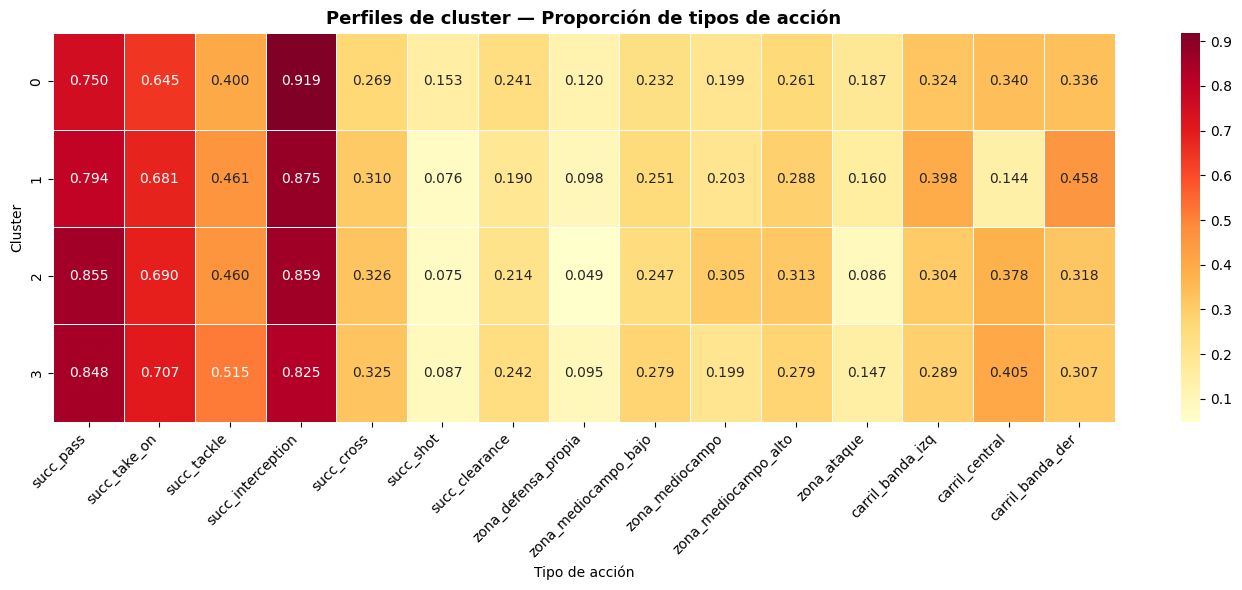

In [245]:
# Caracterización de cada cluster
cluster_profiles = player_vectors.groupby('cluster').mean()

# Heatmap de perfiles
action_cols = [c for c in player_vectors.columns if c not in ['cluster', 'vaep_p90', 'off_total', 'def_total']]

fig, ax = plt.subplots(figsize=(14, OPTIMAL_K + 2))
sns.heatmap(
    cluster_profiles[action_cols[:15]],  # Primeras 15 acciones
    annot=True, fmt='.3f', cmap='YlOrRd',
    linewidths=0.5, ax=ax
)
ax.set_title('Perfiles de cluster — Proporción de tipos de acción', fontsize=13, fontweight='bold')
ax.set_xlabel('Tipo de acción')
ax.set_ylabel('Cluster')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### Perfil de cada cluster con todas las variables (z-score)

El heatmap anterior solo muestra proporciones de tipos de acción. Acá se muestran **todas** las variables del perfil activo
(`PERFIL`) como **desvíos estándar respecto al promedio global**: rojo = el cluster está por encima del promedio en esa variable,
azul = por debajo. Al estar estandarizadas, variables de distinta escala (proporciones, tasas de éxito, VAEP) son comparables.

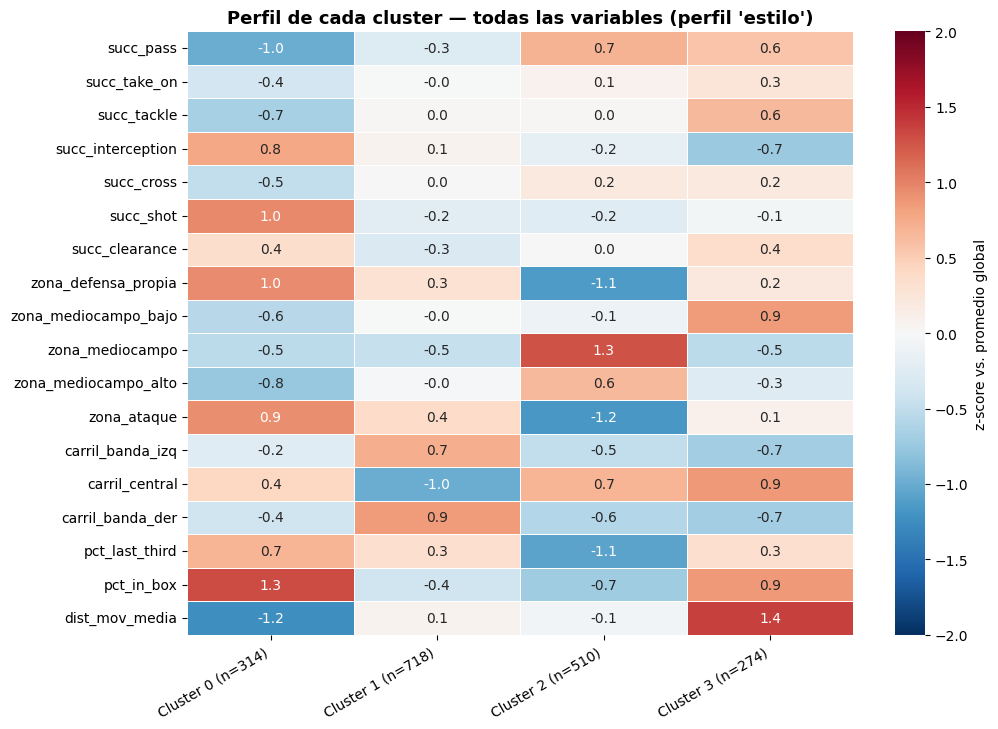

In [246]:
# Heatmap z-score de todas las variables del perfil por cluster
feat_cols = [c for c in player_vectors.columns if c not in ('cluster', 'role_name')]

Z = (player_vectors[feat_cols] - player_vectors[feat_cols].mean()) / (player_vectors[feat_cols].std() + 1e-9)
cluster_z = Z.groupby(player_vectors['cluster']).mean()
n_por_cluster = player_vectors['cluster'].value_counts().sort_index()
cluster_z.index = [f'Cluster {k} (n={n_por_cluster[k]})' for k in cluster_z.index]

fig, ax = plt.subplots(figsize=(1.6 * len(cluster_z) + 4, 0.30 * len(feat_cols) + 2))
sns.heatmap(
    cluster_z.T, annot=True, fmt='.1f', cmap='RdBu_r', center=0, vmin=-2, vmax=2,
    linewidths=0.4, cbar_kws={'label': 'z-score vs. promedio global'}, ax=ax
)
ax.set_title(f"Perfil de cada cluster — todas las variables (perfil '{PERFIL}')",
             fontsize=13, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

#### Composición de cada cluster por posición

¿Los clusters reproducen la posición o la cruzan? Cada barra es un cluster y muestra qué porcentaje de sus jugadores
es Defender / Midfielder / Forward (el número dentro de cada tramo es la cantidad de jugadores).

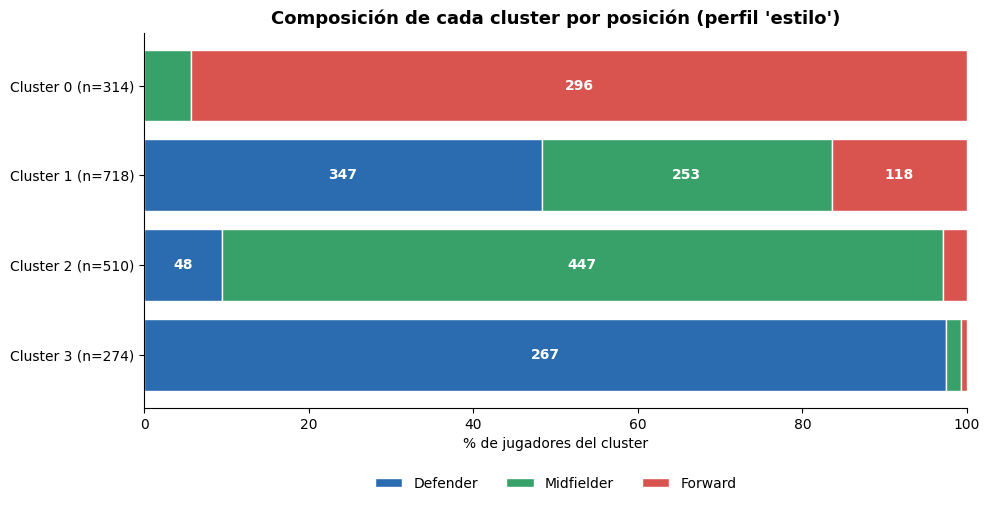

posición,Defender,Midfielder,Forward,Total
cluster,,,,
0,0,18,296,314
1,347,253,118,718
2,48,447,15,510
3,267,5,2,274


In [247]:
# Composición por posición de cada cluster
rol_jug = roles.reindex(player_vectors.index).fillna('Unknown')
tabla_rol = pd.crosstab(player_vectors['cluster'], rol_jug.rename('posición'))
orden = [r for r in ['Defender', 'Midfielder', 'Forward', 'Unknown'] if r in tabla_rol.columns]
tabla_rol = tabla_rol[orden]
tabla_pct = tabla_rol.div(tabla_rol.sum(axis=1), axis=0) * 100

colores = {'Defender': '#2b6cb0', 'Midfielder': '#38a169', 'Forward': '#d9534f', 'Unknown': '#a0aec0'}

fig, ax = plt.subplots(figsize=(10, 0.8 * len(tabla_pct) + 2))
izq = np.zeros(len(tabla_pct))
for rol_ in orden:
    vals = tabla_pct[rol_].values
    ax.barh(range(len(tabla_pct)), vals, left=izq, color=colores[rol_], edgecolor='white', label=rol_)
    for i, (v, n) in enumerate(zip(vals, tabla_rol[rol_].values)):
        if v >= 6:
            ax.text(izq[i] + v / 2, i, f'{n}', ha='center', va='center', color='white', fontsize=10, fontweight='bold')
    izq += vals
ax.set_yticks(range(len(tabla_pct)))
ax.set_yticklabels([f'Cluster {k} (n={tabla_rol.loc[k].sum()})' for k in tabla_pct.index])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('% de jugadores del cluster')
ax.set_title(f"Composición de cada cluster por posición (perfil '{PERFIL}')", fontsize=13, fontweight='bold')
ax.legend(ncol=len(orden), loc='upper center', bbox_to_anchor=(0.5, -0.15), frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

display(tabla_rol.assign(Total=tabla_rol.sum(axis=1)))

## 6. Visualización con UMAP

UMAP (Uniform Manifold Approximation and Projection) es una técnica de reducción de
dimensionalidad superior a t-SNE para grandes datasets. Preserva mejor la estructura global.

Computando UMAP...


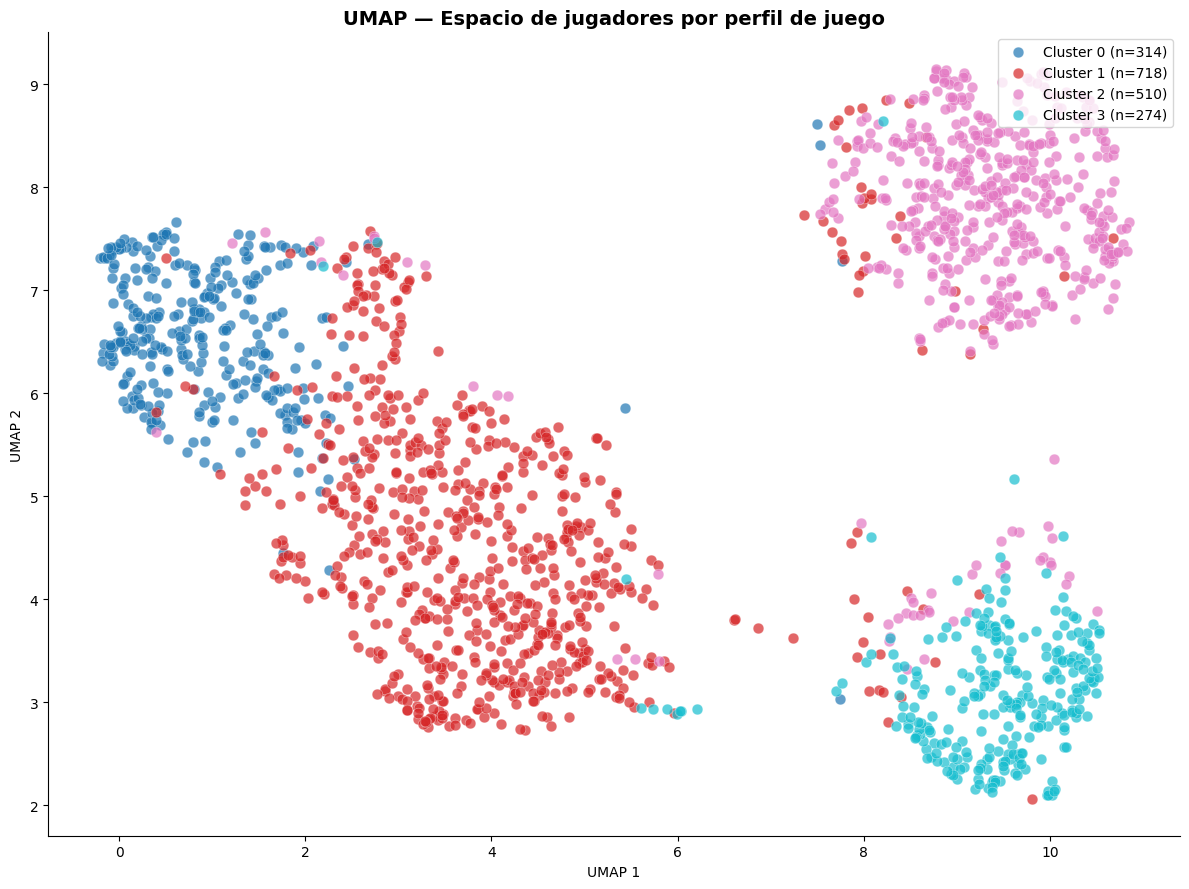

In [248]:
# Reducción dimensional con UMAP
print('Computando UMAP...')
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric='cosine',
    random_state=RANDOM_STATE
)
embedding = reducer.fit_transform(X_cluster)

df_viz = pd.DataFrame({
    'umap_1': embedding[:, 0],
    'umap_2': embedding[:, 1],
    'cluster': cluster_labels,
    'player_id': player_vectors.index
})

# Paleta de colores por cluster
cluster_colors = plt.get_cmap('tab10', OPTIMAL_K)

fig, ax = plt.subplots(figsize=(12, 9))
for k in range(OPTIMAL_K):
    mask_k = df_viz['cluster'] == k
    ax.scatter(
        df_viz.loc[mask_k, 'umap_1'],
        df_viz.loc[mask_k, 'umap_2'],
        c=[cluster_colors(k)],
        s=60, alpha=0.7, edgecolors='white', linewidth=0.3,
        label=f'Cluster {k} (n={mask_k.sum()})'
    )

ax.set_title('UMAP — Espacio de jugadores por perfil de juego', fontsize=14, fontweight='bold')
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.legend(loc='upper right', fontsize=10)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

## 7. Sistema de Scouting por Similitud

Para realizar scouting riguroso separamos conceptualmente el **estilo de juego** del **rendimiento**:
1. **Similitud táctica (Estilo puro):** La distancia matemática (similitud coseno) se calcula **exclusivamente sobre las variables de estilo** (tipos de acción, zonas del campo, carriles, progresión y tasas de éxito), excluyendo métricas de valor. Esto garantiza que la similitud responda a *cómo juega* el futbolista y no a *cuánto rinde*.
2. **Evaluación de impacto (VAEP y xT como variables de resultado):** Una vez identificados los futbolistas con perfil táctico análogo, se contrasta su producción de valor (`vaep_p90` y `xT_p90`).
3. **Detección de oportunidades de mercado:** Si un futbolista tiene alto parecido estilístico con el objetivo pero genera mayor valor (`delta_vaep > 0`), constituye una potencial mejora o reemplazo más productivo.

In [249]:
# ── 1. Matriz de estilo puro para scouting ──────────────────────────────────
# Aislamos las variables tácticas (excluyendo valor, etiquetas de cluster y rol)
cols_excluir = {'cluster', 'role_name', 'player_id', 'vaep_p90', 'off_total', 'def_total', 'xT_p90', 'xT_total', 'games'}
style_cols = [c for c in player_vectors.select_dtypes(include=np.number).columns if c not in cols_excluir and not c.startswith('vaep_')]

scaler_style = StandardScaler()
X_style = scaler_style.fit_transform(player_vectors[style_cols])
print(f"Matriz de estilo para scouting: {X_style.shape[0]} jugadores x {X_style.shape[1]} variables tácticas")

# ── 2. Función de Scouting por Similitud de Estilo + Comparación de Rendimiento ─
def find_similar_players(player_id: int, 
                         player_matrix: np.ndarray = None,
                         player_ids: pd.Index = None,
                         top_n: int = 10,
                         same_role_only: bool = False) -> pd.DataFrame:
    """
    Encuentra los N jugadores más similares basado en similitud coseno sobre el estilo
    y contrasta su rendimiento en VAEP y xT con el jugador objetivo.
    
    Parámetros
    ----------
    player_id      : ID del jugador de referencia (objetivo)
    player_matrix  : matriz de features de estilo (por defecto X_style)
    player_ids     : índice con IDs de jugadores (por defecto player_vectors.index)
    top_n          : número de similares a retornar
    same_role_only : si es True, filtra candidatos de la misma posición/rol
    """
    if player_matrix is None:
        player_matrix = X_style
    if player_ids is None:
        player_ids = player_vectors.index

    if player_id not in player_ids:
        raise ValueError(f"Jugador {player_id} no encontrado en la matriz")
        
    idx = player_ids.get_loc(player_id)
    target_vec = player_matrix[idx].reshape(1, -1)
    
    # Similitud coseno con todos los jugadores sobre estilo
    similarities = cosine_similarity(target_vec, player_matrix)[0]
    
    sim_df = pd.DataFrame({
        "player_id": player_ids,
        "similarity": similarities
    }).set_index("player_id")
    
    # Cruzamos con métricas de rendimiento y metadatos (evitando Index.fillna)
    meta = pd.DataFrame(index=player_ids)
    if "player_names" in globals():
        meta["jugador"] = [player_names.get(pid, str(pid)) for pid in player_ids]
    else:
        meta["jugador"] = player_ids.astype(str)
        
    if "player_role_map" in globals():
        meta["rol"] = [player_role_map.get(pid, "Unknown") for pid in player_ids]
    else:
        meta["rol"] = "Unknown"
        
    meta["cluster"] = player_vectors["cluster"] if "cluster" in player_vectors.columns else -1
    
    # Merge con vaep_by_player y xt_by_player
    perf = meta.join(vaep_by_player.set_index("player_id")[["vaep_p90", "games"]], how="left")
    if "xt_by_player" in globals():
        perf = perf.join(xt_by_player.set_index("player_id")[["xT_p90"]], how="left")
    else:
        perf["xT_p90"] = np.nan
        
    df_merged = sim_df.join(perf, how="inner")
    
    target_meta = df_merged.loc[player_id]
    target_vaep = float(target_meta["vaep_p90"]) if pd.notna(target_meta["vaep_p90"]) else 0.0
    target_role = target_meta["rol"]
    
    # Fila del jugador objetivo
    target_row = df_merged.loc[[player_id]].copy()
    target_row["delta_vaep"] = 0.0
    target_row["tipo"] = "★ OBJETIVO"
    
    # Candidatos ordenados por similitud de estilo
    candidatos = df_merged.drop(index=player_id)
    if same_role_only:
        candidatos = candidatos[candidatos["rol"] == target_role]
        
    candidatos = candidatos.sort_values("similarity", ascending=False).head(top_n).copy()
    candidatos["delta_vaep"] = candidatos["vaep_p90"] - target_vaep
    candidatos["tipo"] = np.where(candidatos["delta_vaep"] > 0, "▲ Mejora", "— Similar")
    
    # Unimos el objetivo al principio para comparación directa
    resultado = pd.concat([target_row, candidatos]).reset_index()
    resultado["similarity"] = resultado["similarity"].round(3)
    resultado["vaep_p90"] = resultado["vaep_p90"].round(3)
    resultado["xT_p90"] = resultado["xT_p90"].round(3)
    resultado["delta_vaep"] = resultado["delta_vaep"].round(3)
    
    return resultado

# ── 3. Ejemplo de Scouting: Jugador de referencia ───────────────────────────
best_row = vaep_by_player.sort_values("vaep_p90", ascending=False).iloc[0]
best_player_id = int(best_row["player_id"])
best_player_name = best_row.get("jugador", str(best_player_id))

print(f"Buscando jugadores similares por estilo a: {best_player_name} (ID: {best_player_id})")
similar_report = find_similar_players(best_player_id, top_n=10)

cols_show = ["tipo", "player_id", "jugador", "rol", "cluster", "similarity", "vaep_p90", "xT_p90", "delta_vaep", "games"]
cols_show = [c for c in cols_show if c in similar_report.columns]
display(similar_report[cols_show])

Matriz de estilo para scouting: 1816 jugadores x 18 variables tácticas
Buscando jugadores similares por estilo a: L. Messi (ID: 3359)


,tipo,player_id,jugador,rol,cluster,similarity,vaep_p90,xT_p90,delta_vaep,games
0,★ OBJETIVO,3359,L. Messi,Forward,0,1.000,0.910,0.199,0.000,36
1,— Similar,25410,A. Pléa,Forward,0,0.839,0.371,0.038,-0.540,35
2,— Similar,89186,P. Dybala,Forward,2,0.796,0.520,0.083,-0.390,33
3,— Similar,99452,A. Milik,Forward,0,0.776,0.226,0.013,-0.685,15
4,— Similar,8326,M. Balotelli,Forward,0,0.756,0.370,0.061,-0.540,28
5,— Similar,21177,G. Pandev,Forward,0,0.730,0.156,0.043,-0.754,31
6,— Similar,3682,A. Griezmann,Forward,0,0.705,0.528,0.066,-0.383,32
7,— Similar,15808,Roberto Firmino,Forward,0,0.704,0.334,0.055,-0.577,37
8,— Similar,70129,Rodrigo,Forward,0,0.698,0.376,0.055,-0.534,37
9,— Similar,3323,G. Higuaín,Forward,0,0.672,0.376,0.029,-0.534,35


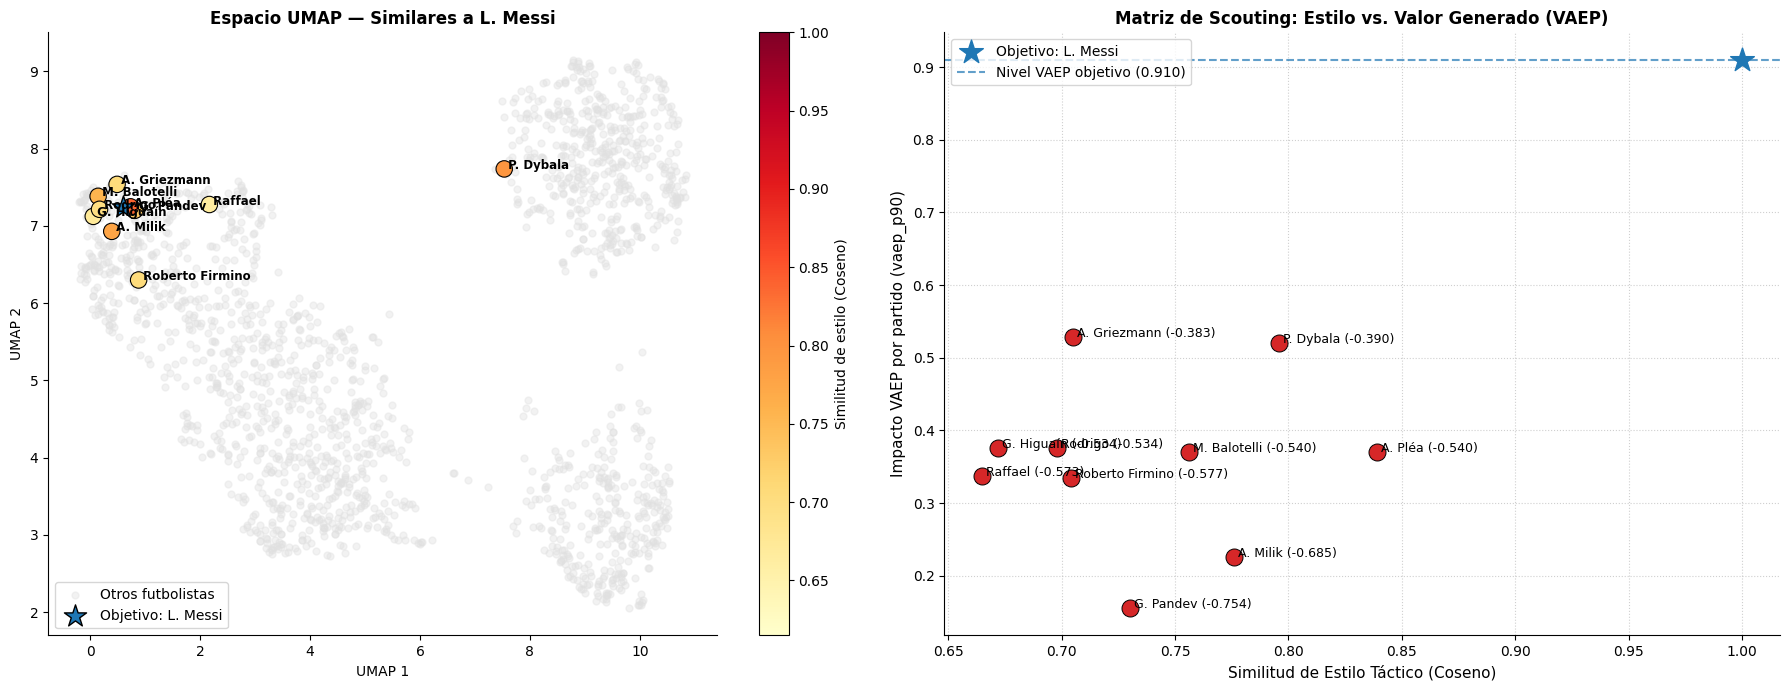

In [235]:
# Visualización del reporte de scouting: UMAP + Dispersión Estilo vs. VAEP
def plot_scouting_report(target_id: int, sim_report: pd.DataFrame, umap_df: pd.DataFrame):
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    target_data = sim_report[sim_report["player_id"] == target_id].iloc[0]
    candidatos = sim_report[sim_report["player_id"] != target_id]

    # Panel 1: Posición en el espacio UMAP
    ax1 = axes[0]
    ax1.scatter(umap_df['umap_1'], umap_df['umap_2'], c='#e0e0e0', s=25, alpha=0.4, zorder=1, label='Otros futbolistas')

    # Puntos de similares coloreados por similitud
    sim_pts = umap_df.merge(candidatos, on='player_id')
    sc = ax1.scatter(
        sim_pts['umap_1'], sim_pts['umap_2'],
        c=sim_pts['similarity'], cmap='YlOrRd', vmin=max(0.0, sim_pts['similarity'].min() - 0.05), vmax=1.0,
        s=140, zorder=3, edgecolors='black', linewidth=0.8
    )
    plt.colorbar(sc, ax=ax1, label='Similitud de estilo (Coseno)')

    # Jugador objetivo
    ref_pt = umap_df[umap_df['player_id'] == target_id]
    if len(ref_pt) > 0:
        ax1.scatter(ref_pt['umap_1'], ref_pt['umap_2'], c='#1f77b4', s=280, marker='*', zorder=5, edgecolors='black', label=f"Objetivo: {target_data['jugador']}")

    for _, r in sim_pts.iterrows():
        ax1.annotate(f" {r['jugador']}", (r['umap_1'], r['umap_2']), fontsize=8.5, fontweight='bold', zorder=6)

    ax1.set_title(f"Espacio UMAP — Similares a {target_data['jugador']}", fontsize=12, fontweight='bold')
    ax1.set_xlabel('UMAP 1')
    ax1.set_ylabel('UMAP 2')
    ax1.legend(loc='lower left')
    ax1.spines[['top', 'right']].set_visible(False)

    # Panel 2: Similitud de estilo vs. Impacto VAEP p90 (Matriz de Scouting)
    ax2 = axes[1]
    for _, r in candidatos.iterrows():
        color = '#2ca02c' if r['delta_vaep'] > 0 else '#d62728'
        ax2.scatter(r['similarity'], r['vaep_p90'], color=color, s=150, zorder=3, edgecolors='black', linewidth=0.7)
        ax2.annotate(f" {r['jugador']} ({r['delta_vaep']:+.3f})", (r['similarity'], r['vaep_p90']), fontsize=9, zorder=5)

    # Línea de referencia del objetivo
    ax2.scatter(target_data['similarity'], target_data['vaep_p90'], color='#1f77b4', marker='*', s=320, zorder=4, label=f"Objetivo: {target_data['jugador']}")
    ax2.axhline(target_data['vaep_p90'], color='#1f77b4', linestyle='--', alpha=0.7, label=f"Nivel VAEP objetivo ({target_data['vaep_p90']:.3f})")

    ax2.set_xlabel('Similitud de Estilo Táctico (Coseno)', fontsize=11)
    ax2.set_ylabel('Impacto VAEP por partido (vaep_p90)', fontsize=11)
    ax2.set_title('Matriz de Scouting: Estilo vs. Valor Generado (VAEP)', fontsize=12, fontweight='bold')
    ax2.grid(True, linestyle=':', alpha=0.6)
    ax2.legend(loc='upper left')
    ax2.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.show()

try:
    plot_scouting_report(best_player_id, similar_report, df_viz)
except Exception as e:
    print(f"Visualización no disponible: {e}")

## 8. Dashboard final de rankings

In [236]:
# Merge de todas las métricas
cluster_df = player_vectors[["cluster"]].reset_index()
if "player_id" not in cluster_df.columns:
    cluster_df = cluster_df.rename(columns={"index": "player_id"})

final_rankings = vaep_by_player.merge(
    xt_by_player[["player_id", "xT_p90", "xT_total"]],
    on="player_id", how="inner"
).merge(
    cluster_df,
    on="player_id", how="left"
)

# Rankeo en cada métrica
final_rankings["rank_vaep"] = final_rankings["vaep_p90"].rank(ascending=False).astype(int)
final_rankings["rank_xt"]   = final_rankings["xT_p90"].rank(ascending=False).astype(int)
final_rankings["rank_avg"]  = ((final_rankings["rank_vaep"] + final_rankings["rank_xt"]) / 2)

print("=== TABLA DE RANKINGS FINALES ===")
cols = ["player_id", "jugador", "vaep_p90", "xT_p90", "rank_vaep", "rank_xt", "rank_avg", "cluster", "games"]
cols = [c for c in cols if c in final_rankings.columns]
print(
    final_rankings.sort_values("rank_avg")
    .head(20)[cols]
    .to_string(index=False)
)


=== TABLA DE RANKINGS FINALES ===
 player_id           jugador  vaep_p90   xT_p90  rank_vaep  rank_xt  rank_avg  cluster  games
     40810            Neymar  0.862119 0.243835          2        1       1.5      1.0     20
      3359          L. Messi  0.910307 0.198674          1        7       4.0      0.0     36
     25770        F. Thauvin  0.554804 0.193301         13        9      11.0      0.0     35
      8317       David Silva  0.421612 0.168070         33       24      28.5      2.0     29
     70096      J. Rodríguez  0.401825 0.165606         42       25      33.5      2.0     23
        54        C. Eriksen  0.359570 0.191777         58       11      34.5      2.0     37
      3802 Philippe Coutinho  0.468437 0.147445         24       52      38.0      2.0     32
      3676      Illarramendi  0.442649 0.149575         27       50      38.5      2.0     36
     26150         R. Mahrez  0.440564 0.146841         29       53      41.0      1.0     36
    388267         L. Bail

In [237]:
# Exportamos resultados finales
output_rankings = './rankings_jugadores_PL_2017_5L.csv'

final_rankings.to_csv(output_rankings, index=False)
print(f'Rankings guardados en: {output_rankings}')

Rankings guardados en: ./rankings_jugadores_PL_2017_5L.csv


## 9. Actividades propuestas

### Ejercicio 1 — Grilla xT extendida
Implementá la grilla xT con resolución más alta (32×24) y compará los resultados.
¿Mayor resolución mejora la métrica o genera overfitting? Usá validación cruzada por partido.

### Ejercicio 2 — VAEP con LightGBM
Entrenaste el modelo VAEP con XGBoost. Ahora reemplazalo con LightGBM.
Compará: tiempo de entrenamiento, AUC, Brier Score y los 10 mejores jugadores por VAEP.
¿Cambia el ranking? ¿En qué porcentaje?

### Ejercicio 3 — Mapas Espaciales de Generación de Valor (Action-Value Flow)
Los números agregados (como el VAEP total o p90) resumen el rendimiento general, pero las visualizaciones espaciales revelan *dónde* y *cómo* se genera ese valor en el campo de juego. Construí una visualización de alto impacto visual para incorporar en tu presentación final:

1. **Mapa de Calor / Grilla Binned de Valor**: Representá sobre el campo (`mplsoccer.Pitch`) la densidad o grilla binned de valor generado (VAEP u ofensivo/defensivo) de un equipo o jugador clave, identificando sus "zonas calientes" de generación de peligro.
2. **Flujo de Acciones de Alto Impacto (Action Flow)**: Para uno o dos jugadores destacados (ej. Kevin De Bruyne, Mohamed Salah, Eden Hazard), filtrá sus acciones con mayor VAEP positivo (top N o percentil 95+) y graficalas como vectores/flechas (`pitch.arrows` o `pitch.lines`), coloreadas por el valor de la acción (usando un colormap continuo como `viridis` o `plasma`) o por tipo de acción (pase, regate, recuperación).
3. **Comparativa Visual Cara a Cara (Side-by-Side)**: Realizá una figura comparativa de dos jugadores con roles similares o rivales para mostrar las diferencias espaciales en su toma de decisiones y zonas de influencia.
4. **Diseño y Estética para la Presentación**: Cuidá la estética visual (paleta de colores profesional, tema pitch/dark, leyendas claras, anotación de VAEP p90 y métricas clave) para que sea un slide visualmente impactante y autoexplicativo en la presentación final.

### Ejercicio 4 — Clustering por liga
Aplicá el pipeline de clustering a todas las ligas disponibles.
¿Los mismos perfiles aparecen en todas las ligas? ¿Hay perfiles de juego únicos
de alguna liga en particular?
---
#### ***Utilizar el clustering original y graficar cantidades por cada cluster asignando un color a cada liga dentro de los grupos. Algo similar al gráfico de "Composicion de cada cluster por posición"***
---
### Ejercicio 5 — Sistema de scouting
Construí un sistema de scouting que dado un jugador 'objetivo' (player_id):
1. Muestre su perfil en radar (métricas normalizadas por posición)
2. Identifique sus 5 jugadores más similares
3. Compare VAEP y xT del objetivo vs. similares
4. Indique si hay jugadores similares con mayor VAEP (posibles mejoras de mercado)
---
#### ***Armar radar con las features del perfil "estilo" a partir de los datos del ej 5***
#### ***Rearmar a partir del ejercicio 7 y 8 tomando otro jugador como referencia que no sea L. Messi y analizar los similares con el nuevo perfil de "estilo" luego incorporar el valor de VAEP y xT como dato extra para comparar performance de jugadores similares.***
---

Aplicalo para encontrar reemplazante de algún jugador histórico de la temporada.

---
**Entregable**: Notebook completo con pipeline VAEP/xT + análisis de clustering + sistema de scouting documentado.